# DeepSeek-V4.1-Flash-1017 on 2x DGX Spark: PixelML EXL3 3 bpw experts on sudoingX's vLLM engine (TP=2)

| Metric | Value | Source |
|---|---|---|
| Decode, 1 stream, code / prose / structured (384 tok, median of 9) | **70.5 / 41.5 / 113.3 tok/s** | measured, this notebook |
| Decode, 1 stream, DSpark drafter off (control) | 32.0 / 31.9 / 31.9 tok/s | measured, this notebook |
| Prefill, 8,192-token prompt (prompt tokens / TTFT) | **1,197 tok/s** (TTFT 6.84 s) | measured, this notebook |
| Memory after load, per node | 104.6 GiB model, about 1 GB free (drafter on) | measured, this notebook |

Launch (recipe launcher, see Reproduce): `MODEL_DIR=<model-dir> MAX_LEN=32768 MAX_SEQS=1 MAX_BATCH=512 KV_BYTES=1073741824 INDEXER_LOGITS_MB=128 EXPANDABLE_SEGMENTS=1 DOCKER_ENV="VLLM_EXL3_HEAD=mxfp8 VLLM_DSPARK_ROUND_MS=37.7,42.1,46.3,49.9,53.0,55.6" ./scripts/launch/dsv41_tp2.sh up`

Evidence: [results/2026-10-24-deepseek-v4.1-flash-1017-exl3-2node-tp2-vllm/](../results/2026-10-24-deepseek-v4.1-flash-1017-exl3-2node-tp2-vllm/). Engine: [sudoingX/dgx-spark-deepseek-v41 @ f8f20b37](https://github.com/sudoingX/dgx-spark-deepseek-v41/tree/f8f20b370e41a3a220bc7d1ab96a61e4daa84964). Weights: [PixelML/DeepSeek-V4.1-Flash-1017-EXL3-3bpw @ 3d095b72](https://huggingface.co/PixelML/DeepSeek-V4.1-Flash-1017-EXL3-3bpw/tree/3d095b724ed4f3abb519cc1cda64c290a0e0b0c5).

**Credits.** The engine, GB10 patches, `vllm_exl3_moe` kernels, launcher and bench scripts are authored by **sudoingX** ([@sudoingX](https://github.com/sudoingX)), Apache-2.0; its RDMA all-reduce ring, L2 prefetch and grouped EXL3 prompt kernels come from TensorFold, authored by **Ash** ([@ashhart](https://github.com/ashhart)) and **bertholomus** ([@bertholomus](https://github.com/bertholomus)). The base model and Engram tables are authored by **DeepSeek-AI** ([@deepseek-ai](https://huggingface.co/deepseek-ai)), MIT. EXL3 and exllamav3 are authored by **Turboderp** ([@turboderp](https://github.com/turboderp)), MIT. The experts quantization script PixelML used is authored by **sfxnz** ([@sfxnz](https://github.com/sfxnz)), MIT. `kit_bench.py` is authored by **bertholomus**. vLLM by the vllm-project.

## Status cell

`LIVE = False` replays the committed receipts. No cell makes a network call.

In [1]:
LIVE = False
EXPERIMENT = "2026-10-24-deepseek-v4.1-flash-1017-exl3-2node-tp2-vllm"
RESULTS_DIR = "../results/" + EXPERIMENT
CHARTS_DIR = "../assets/charts"

In [2]:
import json, glob, os, statistics
from IPython.display import display, Markdown, Image

def load(name):
    with open(os.path.join(RESULTS_DIR, name)) as f:
        return json.load(f)

def table(headers, rows):
    out = "| " + " | ".join(headers) + " |\n| " + " | ".join(["---"] * len(headers)) + " |\n"
    for r in rows:
        out += "| " + " | ".join(str(c) for c in r) + " |\n"
    display(Markdown(out))

def decode_medians(name):
    rows = load(name)["result"]          # kit_bench.py writes {"cmd", "base", "model", "unix", "result": [...]}
    return {r["prompt"]: r for r in rows}

## 1. TL;DR

**Verdict: PixelML's experts-only EXL3 pack serves on sudoingX's engine without any conversion, and the engine is the fastest public 2-Spark stack we have run for this model. The pack, not the engine, is what holds the numbers at 70 / 41 / 113 instead of sudoingX's 104 / 58 / 144.**

- **Measured:** 70.5 / 41.5 / 113.3 tok/s (code / prose / structured, 1 stream, greedy, thinking off, 384 tokens, median of 9, identical text every rep). Drafter off: 32.0 / 31.9 / 31.9. 8K prefill 1,197 tok/s.
- **Why slower than upstream (measured + inferred):** our pack is a uniform 3.0 bpw (sudoingX: 2.7-2.8 bpw mixed) and keeps the dense linears in FP8 and the DSpark drafter in MXFP4 as DeepSeek released them. The drafter alone adds 6.4 ms per round here (37.7 ms at depth 0 vs 31.3 ms with no drafter); sudoingX's EXL3 drafter costs about 1.5 ms. At depth 0 our round is 37.7 ms against their 27.6 ms.
- **Memory (measured):** 104.6 GiB per rank after load with the drafter on, about 1 GB free after warm-up. It fits only at 32K context, 1 sequence, a 1 GiB KV pool and a 512-token prefill chunk. A 2.7 bpw pack leaves 8-9 GB on the same engine (community-reported).
- **TensorFold comparison (community-reported, not measured here):** sudoingX's same-box sessions put bertholomus's TensorFold DeepSeek TP2 engine at 97.7-98.6 / 57.4-58.5 / 140.3-141.3 tok/s on a 2.7 bpw pack; TensorFold cannot load our pack (it expects all-EXL3 tensors), so a same-box TensorFold run needs a pack it reads and about 300 GB more disk per node. Untested here.

Labels: **measured** = this notebook's receipts; **inferred** = our reading of them; **community-reported** = sudoingX's README on their two Sparks.

In [3]:
pins = load("pins.json")["pins"]
table(["Pin", "Value"], [(k, v) for k, v in pins.items()])

| Pin | Value |
| --- | --- |
| model | PixelML/DeepSeek-V4.1-Flash-1017-EXL3-3bpw (routed experts EXL3 K=3 mul1, uncalibrated; non-expert tensors DeepSeek FP8 ue8m0 32x32 as released; DSpark drafter MXFP4 as released); MIT |
| model_revision | 3d095b724ed4f3abb519cc1cda64c290a0e0b0c5 |
| engram_tables | deepseek-ai/DeepSeek-V4.1-Flash-1017 model-00047/00048-of-00048.safetensors @ 1bae0e1088993b9b82de08f59de5be5a34e42170 (read from NVMe at lookup time) |
| recipe | https://github.com/sudoingX/dgx-spark-deepseek-v41 @ f8f20b370e41a3a220bc7d1ab96a61e4daa84964 (v2.0, Apache-2.0): patches 0001-0038, vllm_exl3_moe plugin, launcher scripts/launch/dsv41_tp2.sh, scripts/bench/depth_sweep.sh |
| vllm | https://github.com/vllm-project/vllm @ 6e517b15c1833cf72a7f557ee32524d98682e617 (wheel 0.31.1.dev0+g6e517b15.dsv41gb10, built for sm_121 by the recipe's scripts/build/run_build_gb10.sh) |
| exllamav3 | https://github.com/turboderp-org/exllamav3 v1.6.0 @ 151539c77abc7ab7425d30da7a4e8e3c5c154e7b (MIT), extension only |
| build_env_image | vllm/vllm-openai@sha256:c1c9f6fd5c109ba7f0546a59f5b2f15fb87f64c77782e90a27b648b42a8e67c3 (toolchain only, per the recipe) |
| serving_image | dsv41-serve:v5 built by the recipe's install.sh on one node (local image id sha256:bba1eecc6caac22cb1c144f3f235883e5f4a2ce5c55541bb91a9f5ebb5d9a13b; 50 layers, same layer digests on both nodes); NOT pushed to a registry, rebuild from the pins above |
| bench_client | bertholomus/TensorFold tools/dsv41/kit_bench.py @ fe6f9f7b373db76422ddfa121577238474c0a1b7, sha256 83a4fbeb987032f906cf00d3f6c9dd2fad47dd675e75dd498c4c4188d63a6c0d, run on the head node against localhost |
| nodes | 2x NVIDIA DGX Spark (GB10, sm_121, 128 GB unified LPDDR5X, ~119-121 GiB visible), DGX OS, CUDA 13.0, drivers 580.173.02 (head) / 580.159.03 (worker), ConnectX-7 RoCE v2 200 Gb/s, tensor parallel 2 (one rank per node) |
| model_dir_assembly | hardlinks of the 48 HF shards + index + tokenizer files; exl3_moe_plan.json = plugin tools/make_plan.py --uniform 3 (95.46 GiB experts per rank at TP2); config.json quantization_config.quant_method deepseek_v41_exl3 + exl3_moe block {plan_file, decode_kernel coop, coop_max_tokens 32, fused_rows 256, tp_layout channels, exllamav3_version 1.6.0}; fmt/activation_scheme/scale_fmt/weight_block_size/expert_dtype copied from the pack's non_routed_quantization block |
| launcher_env_final | HEAD=<node-a> WORKER=<node-b> FAB_IF=<fabric-if> FAB_HCA=<fabric-rdma-dev> MODEL_DIR=<model-dir> MAX_LEN=32768 MAX_SEQS=1 MAX_BATCH=512 KV_BYTES=1073741824 INDEXER_LOGITS_MB=128 EXPANDABLE_SEGMENTS=1 DOCKER_ENV="VLLM_EXL3_HEAD=mxfp8 VLLM_DSPARK_ROUND_MS=37.7,42.1,46.3,49.9,53.0,55.6" ./scripts/launch/dsv41_tp2.sh up  (RECIPE_ENV = launcher default; depth policy falls back to conf because the pack ships no dspark_conf_feat_head.npz; TEXT_ONLY=1 default) |
| host_prep | gb10-mem-guard and k3s agent stopped; sync; echo 3 > /proc/sys/vm/drop_caches; echo 1 > /proc/sys/vm/compact_memory (both nodes, before the first boot). No power cap or clock change; stock DGX OS power mode |
| metric | kit_bench.py decode --set b --tokens 384: greedy, thinking off, 64-token warm-up then N reps per prompt, decode tok/s = completion tokens / decode seconds from the stream, median over reps; prefill: 8,192-token prompt, prompt tokens / TTFT. Acceptance = delta of vLLM /metrics spec_decode counters around the run |
| measurement_date | 2026-10-24 |


## 2. Visible results

### 2.1 Decode, one stream, by DSpark policy

`kit_bench.py decode --set b --tokens 384`. The two headline arms come from different boots of the same image and pack; the policy column says what the drafter did.

In [4]:
nospec = decode_medians("decode_b_nospec_boot3.json")
spec4  = decode_medians("decode_b_spec_boot4.json")
final  = decode_medians("decode_b_final_9reps.json")
arms = [("boot 3: drafter off, 64K ctx", nospec, 3), ("boot 4: conf policy, recipe's 2.7 bpw round table", spec4, 3), ("boot 5: conf policy, our measured round table (headline)", final, 9)]
rows = []
for name, d, reps in arms:
    rows.append([name, reps] + [f"{d[p]['decode_tps_median']:.1f}" for p in ("code", "prose", "structured")] + [all(d[p]["identical_texts"] for p in d)])
table(["arm", "reps", "code tok/s", "prose tok/s", "structured tok/s", "identical text across reps"], rows)
# DSpark counters around the headline run
vals = {}
for line in open(os.path.join(RESULTS_DIR, "spec_counters_before_after.txt")):
    k, v = line.split(); vals.setdefault(k, []).append(float(v))
d_drafts = vals["vllm:spec_decode_num_drafts_total"][1] - vals["vllm:spec_decode_num_drafts_total"][0]
d_draft_tok = vals["vllm:spec_decode_num_draft_tokens_total"][1] - vals["vllm:spec_decode_num_draft_tokens_total"][0]
d_acc = vals["vllm:spec_decode_num_accepted_tokens_total"][1] - vals["vllm:spec_decode_num_accepted_tokens_total"][0]
print(f"headline run: {d_drafts:.0f} rounds, {d_draft_tok:.0f} draft tokens, {d_acc:.0f} accepted -> acceptance {d_acc/d_draft_tok:.1%} per draft token, {1 + d_acc/d_drafts:.2f} tokens per round (measured)")

| arm | reps | code tok/s | prose tok/s | structured tok/s | identical text across reps |
| --- | --- | --- | --- | --- | --- |
| boot 3: drafter off, 64K ctx | 3 | 32.0 | 31.9 | 31.9 | True |
| boot 4: conf policy, recipe's 2.7 bpw round table | 3 | 70.8 | 41.3 | 114.4 | True |
| boot 5: conf policy, our measured round table (headline) | 9 | 70.5 | 41.5 | 113.3 | True |


headline run: 3341 rounds, 16705 draft tokens, 7163 accepted -> acceptance 42.9% per draft token, 3.14 tokens per round (measured)


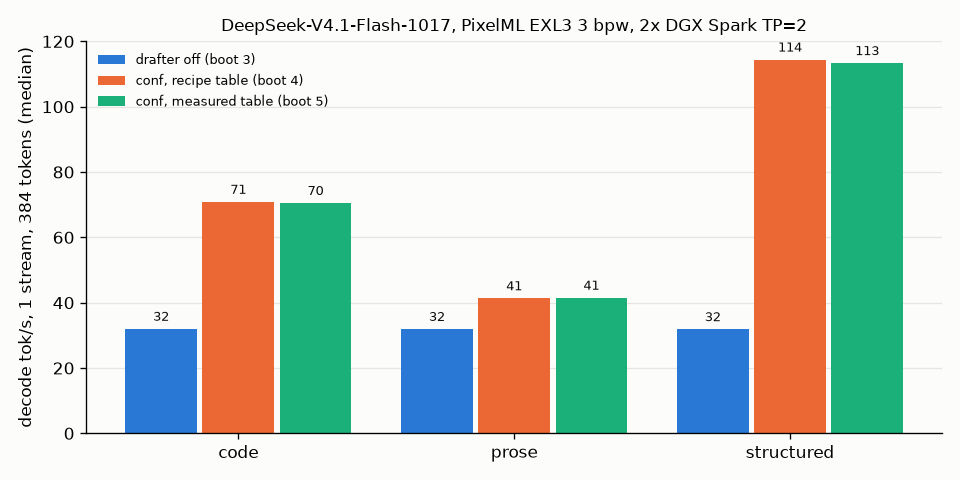

In [5]:
import matplotlib.pyplot as plt
prompts = ["code", "prose", "structured"]
series = [("drafter off (boot 3)", nospec, "#2a78d6"), ("conf, recipe table (boot 4)", spec4, "#eb6834"), ("conf, measured table (boot 5)", final, "#1baf7a")]
fig, ax = plt.subplots(figsize=(8, 4), dpi=120, facecolor="#fcfcfb")
ax.set_facecolor("#fcfcfb")
w = 0.26
for i, (label, d, c) in enumerate(series):
    xs = [j + (i - 1) * (w + 0.02) for j in range(3)]
    ys = [d[p]["decode_tps_median"] for p in prompts]
    ax.bar(xs, ys, width=w, color=c, label=label, linewidth=0)
    for x, y in zip(xs, ys):
        ax.text(x, y + 1.5, f"{y:.0f}", ha="center", va="bottom", fontsize=8, color="#0b0b0b")
ax.set_xticks(range(3)); ax.set_xticklabels(prompts)
ax.set_ylabel("decode tok/s, 1 stream, 384 tokens (median)")
ax.set_title("DeepSeek-V4.1-Flash-1017, PixelML EXL3 3 bpw, 2x DGX Spark TP=2", fontsize=10)
for s in ("top", "right"): ax.spines[s].set_visible(False)
ax.yaxis.grid(True, color="#e6e5e1", linewidth=0.8); ax.set_axisbelow(True)
ax.legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()
os.makedirs(CHARTS_DIR, exist_ok=True)
for ext in ("png", "svg"):
    fig.savefig(os.path.join(CHARTS_DIR, f"{EXPERIMENT}-decode.{ext}"), facecolor=fig.get_facecolor())
plt.close(fig); display(Image(filename=os.path.join(CHARTS_DIR, f"{EXPERIMENT}-decode.png")))

### 2.2 Depth sweep: round cost and tokens per round by fixed draft depth

`scripts/bench/depth_sweep.sh` (sudoingX) on boot 5: each fixed depth 0..5, then `conf` with the round-cost table the fixed depths just measured. 2 reps per prompt, 384 tokens. `ms/round` is the verify-step time; depth 0 means the drafter runs but no draft is verified.

| policy | code tok/s | tok/round | ms/round | prose tok/s | tok/round | ms/round | structured tok/s | tok/round | ms/round |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| fixed5 | 66.5 | 3.75 | 56.4 | 37.0 | 2.06 | 55.6 | 114.4 | 5.98 | 52.3 |
| fixed4 | 66.8 | 3.58 | 53.6 | 38.2 | 2.03 | 53.0 | 97.3 | 4.97 | 51.1 |
| fixed3 | 64.9 | 3.27 | 50.4 | 39.8 | 1.98 | 49.9 | 81.7 | 3.99 | 48.8 |
| fixed2 | 54.7 | 2.55 | 46.6 | 40.5 | 1.87 | 46.2 | 64.7 | 2.99 | 46.3 |
| fixed1 | 44.4 | 1.87 | 42.1 | 37.9 | 1.58 | 41.8 | 46.8 | 1.99 | 42.6 |
| fixed0 | 26.5 | 1.00 | 37.7 | 26.5 | 1.00 | 37.7 | 26.7 | 1.00 | 37.5 |
| conf | 70.3 | 3.79 | 53.9 | 41.6 | 1.89 | 45.4 | 113.8 | 5.98 | 52.6 |


measured round-cost table (median over prompts), depths 0..5: 37.7, 42.1, 46.3, 49.9, 53.0, 55.6 ms


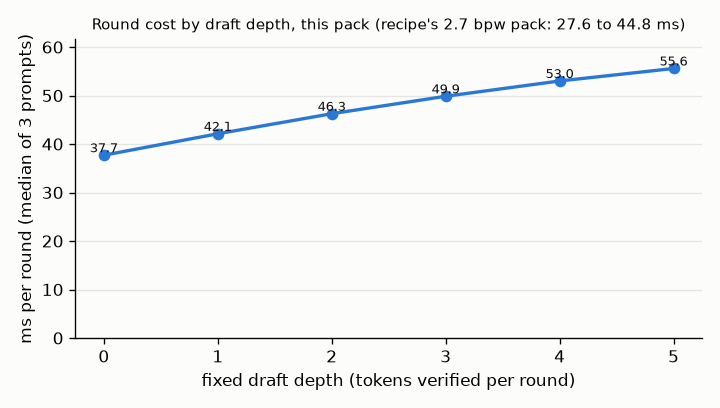

In [6]:
pol = ["fixed5", "fixed4", "fixed3", "fixed2", "fixed1", "fixed0", "conf"]
rows = []; cost = {}
for tag in pol:
    rs = json.load(open(os.path.join(RESULTS_DIR, "depth_sweep", f"probe_{tag}.json")))
    r = [tag]
    for p in prompts:
        pr = [x for x in rs if x["prompt"] == p]
        tps = statistics.median(x["decode_tps"] for x in pr); tpr = statistics.median(x["tokens_per_step"] for x in pr); ms = statistics.median(x["ms_per_step"] for x in pr)
        r += [f"{tps:.1f}", f"{tpr:.2f}", f"{ms:.1f}"]
        if tag.startswith("fixed"): cost.setdefault(int(tag[5:]), []).append(ms)
    rows.append(r)
table(["policy", "code tok/s", "tok/round", "ms/round", "prose tok/s", "tok/round", "ms/round", "structured tok/s", "tok/round", "ms/round"], rows)
tbl = [statistics.median(cost[d]) for d in sorted(cost)]
print("measured round-cost table (median over prompts), depths 0..5:", ", ".join(f"{v:.1f}" for v in tbl), "ms")
fig, ax = plt.subplots(figsize=(6, 3.4), dpi=120, facecolor="#fcfcfb"); ax.set_facecolor("#fcfcfb")
ax.plot(sorted(cost), tbl, color="#2a78d6", linewidth=2, marker="o", markersize=6)
for d, v in zip(sorted(cost), tbl): ax.text(d, v + 0.6, f"{v:.1f}", ha="center", fontsize=8, color="#0b0b0b")
ax.set_xlabel("fixed draft depth (tokens verified per round)"); ax.set_ylabel("ms per round (median of 3 prompts)")
ax.set_title("Round cost by draft depth, this pack (recipe's 2.7 bpw pack: 27.6 to 44.8 ms)", fontsize=9)
for s in ("top", "right"): ax.spines[s].set_visible(False)
ax.yaxis.grid(True, color="#e6e5e1", linewidth=0.8); ax.set_axisbelow(True); ax.set_ylim(0, max(tbl) + 6)
fig.tight_layout()
for ext in ("png", "svg"):
    fig.savefig(os.path.join(CHARTS_DIR, f"{EXPERIMENT}-round-ms.{ext}"), facecolor=fig.get_facecolor())
plt.close(fig); display(Image(filename=os.path.join(CHARTS_DIR, f"{EXPERIMENT}-round-ms.png")))

### 2.3 Prefill, power, memory

In [7]:
p4 = load("prefill_8k_boot4.json")["result"][0]; p5 = load("prefill_8k_final.json")["result"][0]
table(["arm", "prompt tokens", "TTFT s", "prefill tok/s"], [
    ("boot 4 (first 8K prompt after boot)", p4["prompt_tokens"], f"{p4['ttft_s']:.2f}", f"{p4['prefill_tps']:.0f}"),
    ("boot 5 (after the depth sweep)", p5["prompt_tokens"], f"{p5['ttft_s']:.2f}", f"{p5['prefill_tps']:.0f}")])
pw = [l.strip().split(",") for l in open(os.path.join(RESULTS_DIR, "nvsmi_head_during_decode.csv")) if l.strip()]
watts = [float(r[0].split()[0]) for r in pw]; temps = [float(r[1]) for r in pw]; util = [float(r[2].split()[0]) for r in pw]
print(f"head node during the headline decode run, {len(pw)} samples at 5 s: GPU power mean {statistics.mean(watts):.0f} W, max {max(watts):.0f} W; temperature max {max(temps):.0f} C; utilization mean {statistics.mean(util):.0f} % (measured; stock power mode, no cap)")
print("memory (measured, from the serve logs): model load 100.62 GiB/rank with the drafter off, 105.15 with it (BF16 head), 104.63 with the MXFP8 head; MemAvailable after warm-up about 1.2-2.0 GB (head) / 0.9-1.1 GB (worker)")

| arm | prompt tokens | TTFT s | prefill tok/s |
| --- | --- | --- | --- |
| boot 4 (first 8K prompt after boot) | 8192 | 9.42 | 870 |
| boot 5 (after the depth sweep) | 8192 | 6.84 | 1197 |


head node during the headline decode run, 40 samples at 5 s: GPU power mean 51 W, max 66 W; temperature max 73 C; utilization mean 81 % (measured; stock power mode, no cap)
memory (measured, from the serve logs): model load 100.62 GiB/rank with the drafter off, 105.15 with it (BF16 head), 104.63 with the MXFP8 head; MemAvailable after warm-up about 1.2-2.0 GB (head) / 0.9-1.1 GB (worker)


### 2.4 Reading the numbers

- **The pack is compatible as published (measured).** The plugin reads `layers.L.ffn.experts.E.w{1,2,3}.{trellis,suh,svh,mul1}`, the keys exllamav3 writes and the keys sfxnz's quantization script wrote into the PixelML pack. Only a `exl3_moe_plan.json` (uniform K=3, from the plugin's `tools/make_plan.py --uniform 3`) and a `quant_method: deepseek_v41_exl3` config block were added; every weight file is a hardlink of the Hugging Face shard.
- **Round cost explains the gap (measured + inferred).** Depth-0 round 37.7 ms here vs 27.6 ms in the recipe's table for its 2.7 bpw pack. Of the 10 ms: about 6.4 ms is the drafter (31.3 ms per step with the drafter off), which here runs MXFP4 experts through vLLM's MoE path instead of the recipe's EXL3 drafter on `exl3_smoe`; the rest is 3.0 vs 2.7 bpw of expert bytes and FP8 Marlin dense linears vs EXL3 K5.
- **Tokens per round are comparable (measured):** 3.79 / 1.89 / 5.98 with `conf` here vs 4.47 / 2.10 / 5.91 community-reported for the v2.0 pack with its fitted depth model. Our pack ships no `dspark_conf_feat_head.npz`, so the policy is the confidence head alone.
- **The measured table changed little (measured):** boot 4 (recipe's table) 70.8 / 41.3 / 114.4 vs boot 5 (our table) 70.5 / 41.5 / 113.3, inside run-to-run noise.
- **Memory is the hard limit (measured).** 3.0 bpw costs about 9.5 GiB per rank over 2.7 bpw. The serve wedged twice at 0 free before the knobs above (see the appendix).

## 3. Reproduce

Hardware: two DGX Sparks (GB10, 128 GB each) cabled with ConnectX-7, an IPv4 on the fabric port of each, Docker with the NVIDIA container toolkit, passwordless ssh from a control machine to both, about 440 GB free per node (397 GiB model folder + the images). Expect about 30 minutes for the engine build on one Spark and 5-7 minutes per boot.

```bash
# 1. recipe on both nodes (pinned), engine images built on one node and copied to the other (install.sh, ~30 min)
git clone https://github.com/sudoingX/dgx-spark-deepseek-v41 ~/dsv41_recipe && git -C ~/dsv41_recipe checkout f8f20b370e41a3a220bc7d1ab96a61e4daa84964
cd ~/dsv41_recipe && PEER=<node-b> ./install.sh      # vLLM 6e517b15 wheel for sm_121, exllamav3 v1.6.0, dsv41-serve:v5

# 2. weights (both nodes, same absolute path): PixelML pack + DeepSeek's two Engram shards (1017 revision)
hf download PixelML/DeepSeek-V4.1-Flash-1017-EXL3-3bpw --revision 3d095b724ed4f3abb519cc1cda64c290a0e0b0c5 --local-dir <model-dir>
hf download deepseek-ai/DeepSeek-V4.1-Flash-1017 model-00047-of-00048.safetensors model-00048-of-00048.safetensors \
  --revision 1bae0e1088993b9b82de08f59de5be5a34e42170 --local-dir <model-dir>

# 3. plugin plan + config (both nodes): uniform K=3 plan, quant_method deepseek_v41_exl3
cd ~/dsv41_recipe/patches/exl3_moe && python3 tools/make_plan.py --uniform 3 -o <model-dir>/exl3_moe_plan.json
python3 - <<'EOF'
import json; p = "<model-dir>/config.json"; cfg = json.load(open(p)); q = cfg["quantization_config"]; nr = q["non_routed_quantization"]
cfg["quantization_config"] = {"quant_method": "deepseek_v41_exl3", "fmt": nr["fmt"], "activation_scheme": nr["activation_scheme"],
  "scale_fmt": nr["scale_fmt"], "weight_block_size": nr["weight_block_size"], "expert_dtype": nr["expert_dtype"],
  "exl3_moe": {"plan_file": "exl3_moe_plan.json", "decode_kernel": "coop", "coop_max_tokens": 32, "fused_rows": 256, "tp_layout": "channels", "exllamav3_version": "1.6.0"}}
json.dump(cfg, open(p, "w"), indent=2)
EOF

# 4. host prep (both nodes, needs sudo): stop any memory guard / orchestrator agent, then
sync; echo 3 | sudo tee /proc/sys/vm/drop_caches; echo 1 | sudo tee /proc/sys/vm/compact_memory

# 5. serve (from the control machine); FAB_IF/FAB_HCA = your fabric port and its RoCE device
HEAD=<node-a> WORKER=<node-b> FAB_IF=<fabric-if> FAB_HCA=<fabric-rdma-dev> MODEL_DIR=<model-dir> \
MAX_LEN=32768 MAX_SEQS=1 MAX_BATCH=512 KV_BYTES=1073741824 INDEXER_LOGITS_MB=128 EXPANDABLE_SEGMENTS=1 \
DOCKER_ENV="VLLM_EXL3_HEAD=mxfp8 VLLM_DSPARK_ROUND_MS=37.7,42.1,46.3,49.9,53.0,55.6" ./scripts/launch/dsv41_tp2.sh up

# 6. measure (on the head node)
curl -LO https://raw.githubusercontent.com/bertholomus/TensorFold/fe6f9f7b373db76422ddfa121577238474c0a1b7/tools/dsv41/kit_bench.py
sha256sum kit_bench.py   # 83a4fbeb987032f906cf00d3f6c9dd2fad47dd675e75dd498c4c4188d63a6c0d
python3 kit_bench.py --base http://localhost:8000 --model dsv41 decode --set b --tokens 384 --reps 9
python3 kit_bench.py --base http://localhost:8000 --model dsv41 prefill --lengths 8192
```

Endpoint: OpenAI-compatible on the head node, port 8000, model `dsv41`, `chat_template_kwargs: {"enable_thinking": false}` for the numbers above. The serving image is not published to a registry; the build is deterministic from the pins (base image digest, vLLM and exllamav3 commits, the recipe's patches).

## 4. Appendix

<details>
<summary>Boot history, failures and their fixes</summary>

| boot | knobs | outcome |
|---|---|---|
| 1 | launcher defaults, `MAX_LEN` 131072, drafter on | model load 105.15 GiB/rank; both nodes reached about 0 MemAvailable; worker never finished warm-up. Stopped after 30 min. |
| 2 | drafter off, `MAX_LEN` 65536, `MAX_BATCH` 1024, `INDEXER_LOGITS_MB` 128, `EXPANDABLE_SEGMENTS` 1 | load 100.62 GiB/rank; rank 1 hung forever on a stale `lock` file in `~/.cache/dsv41-serve/torch_extensions/exl3_l2pf_*/` left by the killed boot 1 (torch's extension FileBaton). Deleting the lock made it import a `.so` that was never built. Stopped. |
| 3 | boot-2 knobs, every JIT extension dir without a `.so` deleted first | served. 32.0 / 31.9 / 31.9 tok/s. |
| 4 | drafter on, `MAX_LEN` 32768, `MAX_SEQS` 1, `MAX_BATCH` 512, `KV_BYTES` 1 GiB, MXFP8 head | served. 70.8 / 41.3 / 114.4; 8K prefill 870 tok/s on the first long prompt; 0.8-1.1 GB free on the worker. |
| 5 | boot-4 knobs, depth policy `fixed:5` + depth file for the sweep | served. Sweep, then headline 70.5 / 41.5 / 113.3 with `conf` and the measured table; 8K prefill 1,197 tok/s. |

Lessons: a killed boot leaves JIT build locks that hang the next boot silently (no log line, 100-300 % CPU on the worker); delete any `torch_extensions/<ext>` dir without a `.so` before `up`. GB10 unified memory gives no clean OOM: watch `MemAvailable` on both nodes during load and stop below about 1 GB. The launcher's page-cache drop needs passwordless sudo; without it, run the drop by hand before `up`.

Not done here: 32K prefill and the long-context needles (memory too tight on this pack), two-stream concurrency (`MAX_SEQS` 1), quality (KLD / suites) of the PixelML pack on this engine, a same-box TensorFold run. The fastest public configuration of this engine, per its author, is the v1.2 2.7 bpw pack on the v5 engine (106.4 / 61.8 / 149.1 tok/s, community-reported); our own 4x CMP 170HX server runs the same pack on a different stack and is documented elsewhere; it is not comparable (different hardware).

Cost: one engine build (31 min) and five boots on two Sparks, about 3.5 hours wall clock, no cloud spend.
</details>